# This project focuses on collecting, cleaning, and analyzing top-rated movies using the TMDB API.
The goal is to analyze ratings, vote counts, and popularity to uncover trends in movie data.

## Phase 1: Data Collection Setup
Loading API keys securely from Colab Secrets and importing necessary libraries.

In [71]:
import requests
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from google.colab import userdata


API_KEY = userdata.get('TMDB_API_KEY')

### Fetching Top Movies Data
Making GET requests to the TMDB API across multiple pages to fetch top-rated movies into a raw list.

In [72]:
movies_list = []
for page in range(1,11):
  url = f"https://api.themoviedb.org/3/movie/top_rated?api_key={API_KEY}&language=en-US&page={page}"
  data = requests.get(url)
  newdata = data.json()

  for movie in newdata['results']:
    movies_list.append(
        {
          'title': movie.get('title'),
          'release_date': movie.get('release_date'),
          'popularity': movie.get('popularity'),
          'vote_average': movie.get('vote_average'),
          'vote_count': movie.get('vote_count'),
          'original_language': movie.get('original_language')
        }
    )

df = movies_list
ndf = pd.DataFrame(df)

## Phase 2: Data Cleaning & Export
Saving raw data to a CSV file and verifying data integrity, missing values, and column structure.

In [74]:

dff = pd.read_csv("tmdb_movies.csv")

# Data inspection
print("Shape of Dataset:", dff.shape)
print("\nMissing Values:\n", dff.isnull().sum())
dff.info()

Shape of Dataset: (200, 6)

Missing Values:
 title                0
release_date         0
popularity           0
vote_average         0
vote_count           0
original_language    0
dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   title              200 non-null    object 
 1   release_date       200 non-null    object 
 2   popularity         200 non-null    float64
 3   vote_average       200 non-null    float64
 4   vote_count         200 non-null    int64  
 5   original_language  200 non-null    object 
dtypes: float64(2), int64(1), object(3)
memory usage: 9.5+ KB


## Phase 3: Exploratory Data Analysis (EDA)

### 1. Rating Distribution
Visualizing the distribution of `vote_average` using a histogram to analyze the rating spread.

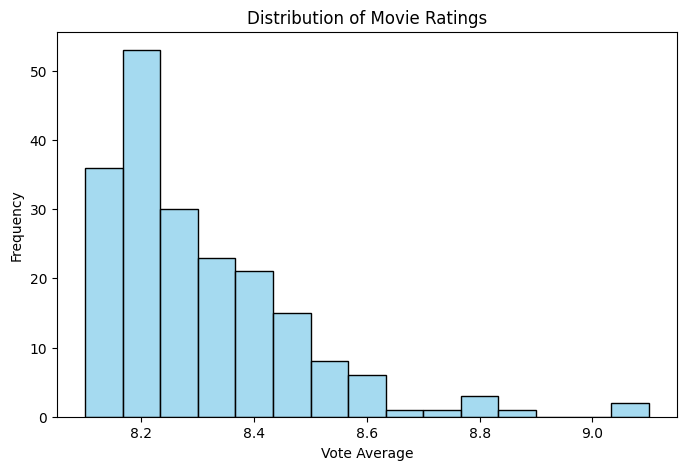

In [76]:
plt.figure(figsize=(8, 5))
sns.histplot(dff['vote_average'], color='skyblue')
plt.title("Distribution of Movie Ratings")
plt.xlabel("Vote Average")
plt.ylabel("Frequency")
plt.show()

### 2. Rating vs Vote Count Relationship
Scatter plot to analyze how total `vote_count` correlates with `vote_average`.

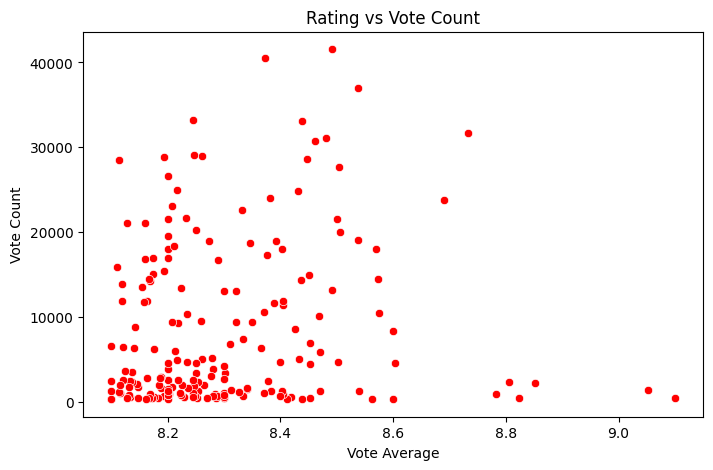

In [78]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=dff, x='vote_average', y='vote_count', color='red')
plt.title("Rating vs Vote Count")
plt.xlabel("Vote Average")
plt.ylabel("Vote Count")
plt.show()

## 🔍 Phase 4: Data Insights & Ranking
Extracting the top most popular movies using pandas aggregation tools.

In [82]:
top5_popular = dff.nlargest(5, 'popularity')[['title', 'popularity', 'vote_average', 'vote_count']]
display(top5_popular)

,title,popularity,vote_average,vote_count
25,Spider-Man: Brand New Day,1659.2083,8.470,5881
8,Project Hail Mary,1571.7388,8.600,8403
64,Runner,185.9514,8.334,679
83,Toy Story 5,136.9948,8.300,2675
154,Obsession,107.7502,8.175,6236


## Key Findings & Conclusion
- **Rating Distribution:** The majority of top-rated movies fall within the `8.2` to `8.3` rating range.
- **Vote Count Dynamics:** Movies with extreme high ratings (>8.8) tend to have significantly lower vote counts, whereas popular commercial blockbusters stay in the `8.2`-`8.4` range with high vote counts.
- **Pipeline Integrity:** Data was cleanly ingested from REST API, validated, exported to CSV, and analyzed without missing data issues.